#Importando bibliotecas

In [54]:
#Importações de visualização
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#Importações para os algoritmos
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report


#Manipulando os dados

In [3]:
!unzip digit-recognizer.zip

Archive:  digit-recognizer.zip
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [13]:
df_train = pd.read_csv('train.csv')
df_train.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
df_test = pd.read_csv('test.csv')
X_test = df_test
df_test.head()

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [15]:
y_train = df_train['label']
X_train = df_train.drop('label', axis=1)
X_train.shape

(42000, 784)

In [16]:
X_train_standardized = X_train / 255.0
X_test_standardized = X_test / 255.0

In [17]:
x_train, x_test, y_train, y_test = train_test_split(X_train_standardized, y_train, test_size=0.2, random_state=42)

#Criando a rede CNN

In [26]:
# Redimensionando os dados de (N, 784) para (N, 28, 28, 1)
x_train = np.array(x_train).reshape(-1, 28, 28, 1)
x_test = np.array(x_test).reshape(-1, 28, 28, 1)

print("Novo formato do x_train:", x_train.shape)
print("Novo formato do x_test:", x_test.shape)

Novo formato do x_train: (33600, 28, 28, 1)
Novo formato do x_test: (8400, 28, 28, 1)


In [28]:
num_classes = 10

model = keras.Sequential(
    [
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ]
)

In [29]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#Testando o modelo

In [30]:
model.fit(x_train, y_train, batch_size=128, epochs=5)

Epoch 1/5
263/263 ━━━━━━━━━━━━━━━━━━━━ 28s 103ms/step - accuracy: 0.8516 - loss: 0.4786
Epoch 2/5
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 103ms/step - accuracy: 0.9574 - loss: 0.1403
Epoch 3/5
263/263 ━━━━━━━━━━━━━━━━━━━━ 27s 101ms/step - accuracy: 0.9674 - loss: 0.1050
Epoch 4/5
263/263 ━━━━━━━━━━━━━━━━━━━━ 27s 103ms/step - accuracy: 0.9725 - loss: 0.0883
Epoch 5/5
263/263 ━━━━━━━━━━━━━━━━━━━━ 26s 100ms/step - accuracy: 0.9765 - loss: 0.0757


In [35]:
train_loss, train_acc = model.evaluate(x_train, y_train, verbose=0)
print(f"Acurácia no treino: {train_acc*100:.2f}%")

Acurácia no treino: 98.72%


In [36]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Acurácia no teste: {test_acc*100:.2f}%")

Acurácia no teste: 98.30%


In [37]:
model.save("cnn_mnist.keras")
print("Modelo salvo em cnn_mnist.keras")

Modelo salvo em cnn_mnist.keras


#Resultados do treino

In [49]:
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

263/263 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step


In [51]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       816
           1       0.99      1.00      0.99       909
           2       0.99      0.98      0.98       846
           3       0.99      0.98      0.98       937
           4       0.98      0.98      0.98       839
           5       0.98      0.98      0.98       702
           6       0.98      0.99      0.98       785
           7       0.99      0.99      0.99       893
           8       0.97      0.98      0.98       835
           9       0.98      0.98      0.98       838

    accuracy                           0.98      8400
   macro avg       0.98      0.98      0.98      8400
weighted avg       0.98      0.98      0.98      8400



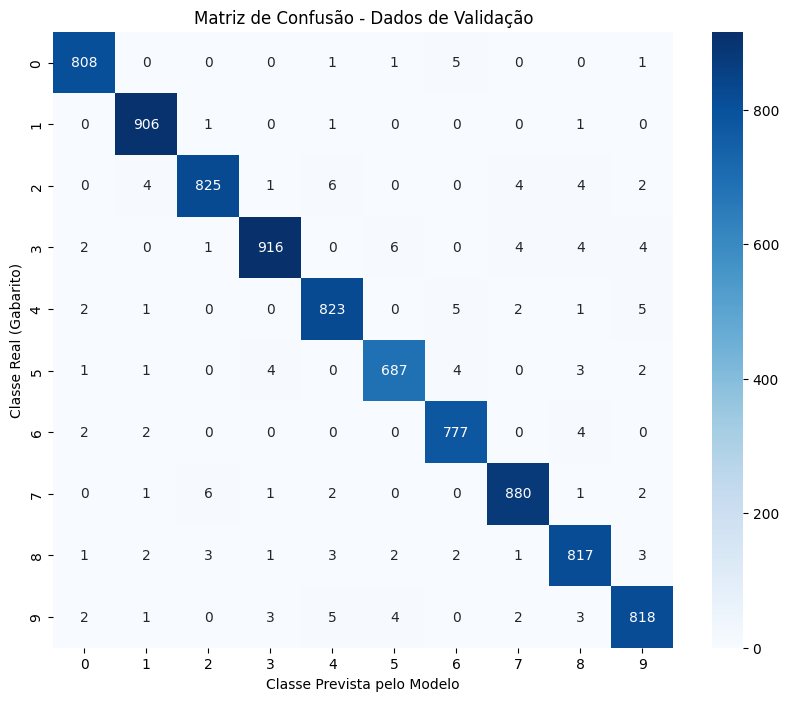

In [52]:
#Gerando matriz de confusão

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))

plt.title('Matriz de Confusão - Dados de Validação')
plt.ylabel('Classe Real (Gabarito)')
plt.xlabel('Classe Prevista pelo Modelo')
plt.show()

#Resultado Final

In [45]:
# 1. Redimensionar o conjunto de teste final (test.csv) para o formato da rede (N, 28, 28, 1)
X_test_final = np.array(X_test_standardized).reshape(-1, 28, 28, 1)
print("Formato do conjunto de teste final:", X_test_final.shape)

# 2. Fazer as previsões usando o modelo treinado
predictions = model.predict(X_test_final)

# 3. Obter a classe com maior probabilidade para cada imagem
predicted_classes = np.argmax(predictions, axis=1)

# 4. Criar o DataFrame de submissão no padrão do Kaggle (ImageId, Label)
submission_df = pd.DataFrame({
    "ImageId": range(1, len(predicted_classes) + 1),
    "Label": predicted_classes
})

# Exibir as primeiras linhas da submissão para conferência
display(submission_df.head())

# 5. Salvar em um arquivo CSV
submission_df.to_csv('submission.csv', index=False)
print("Arquivo 'submission.csv' gerado com sucesso!")

Formato do conjunto de teste final: (28000, 28, 28, 1)
875/875 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step


,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,9
4,5,3


Arquivo 'submission.csv' gerado com sucesso!


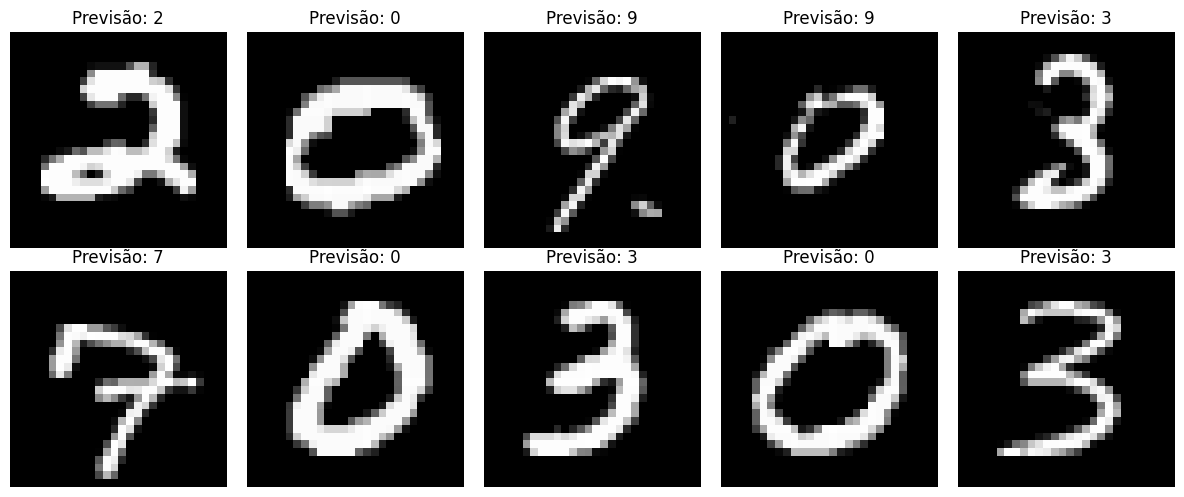

In [44]:
# Visualizar as primeiras 10 imagens de teste e as previsões do modelo
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # Redimensiona de volta para 28x28 para exibir
    plt.imshow(X_test_final[i].reshape(28, 28), cmap='gray')
    plt.title(f"Previsão: {predicted_classes[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()